Import the required libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pickle
import joblib
import os

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("All libraries imported successfully!")

All libraries imported successfully!


Create a dataset

In [2]:
X, y = make_moons(
    n_samples=1000,
    noise=0.15,
    random_state=42
)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Normalize the input features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training samples: 800
Testing samples: 200
Number of input features: 2


Visualize the dataset

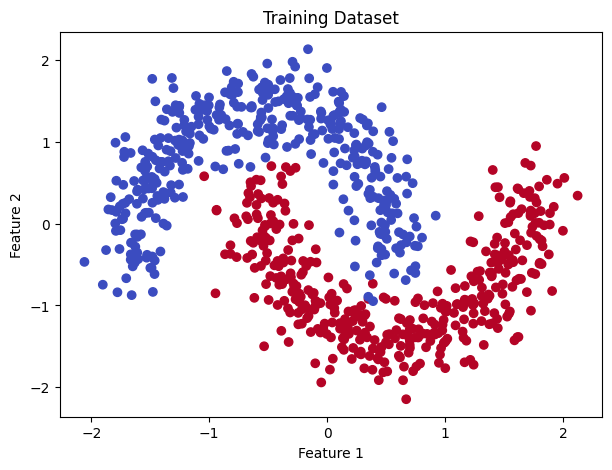

In [3]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="coolwarm"
)

plt.title("Training Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Train a simple machine learning model

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 85.0 %


Save the model using pickle

In [5]:
with open("model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully using pickle!")

Model saved successfully using pickle!


Load the model using pickle

In [6]:
with open("model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

predictions = loaded_model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Loaded Model Accuracy:", round(accuracy * 100, 2), "%")

Loaded Model Accuracy: 85.0 %


Save and load the model using joblib

In [7]:
# Save the trained model
joblib.dump(model, "model.joblib")

print("Model saved using joblib!")

# Load the model
loaded_model = joblib.load("model.joblib")

# Test the loaded model
predictions = loaded_model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Joblib Model Accuracy:", round(accuracy * 100, 2), "%")

Model saved using joblib!
Joblib Model Accuracy: 85.0 %


| Feature            | Pickle                   | Joblib                   |
| ------------------ | ------------------------ | ------------------------ |
| Purpose            | Serialize Python objects | Serialize Python objects |
| Save method        | `pickle.dump()`          | `joblib.dump()`          |
| Load method        | `pickle.load()`          | `joblib.load()`          |
| Large NumPy arrays | Supported                | Particularly well suited |
| File extension     | `.pkl`                   | `.joblib`                |


Perceptrons and Activation Functions

In [8]:
def perceptron(inputs, weights, bias):
    z = np.dot(inputs, weights) + bias

    output = 1 if z >= 0 else 0

    return output


# Example
inputs = np.array([1, 0])
weights = np.array([0.5, -0.3])
bias = -0.1

output = perceptron(inputs, weights, bias)

print("Perceptron Output:", output)

Perceptron Output: 1


Implement common activation functions

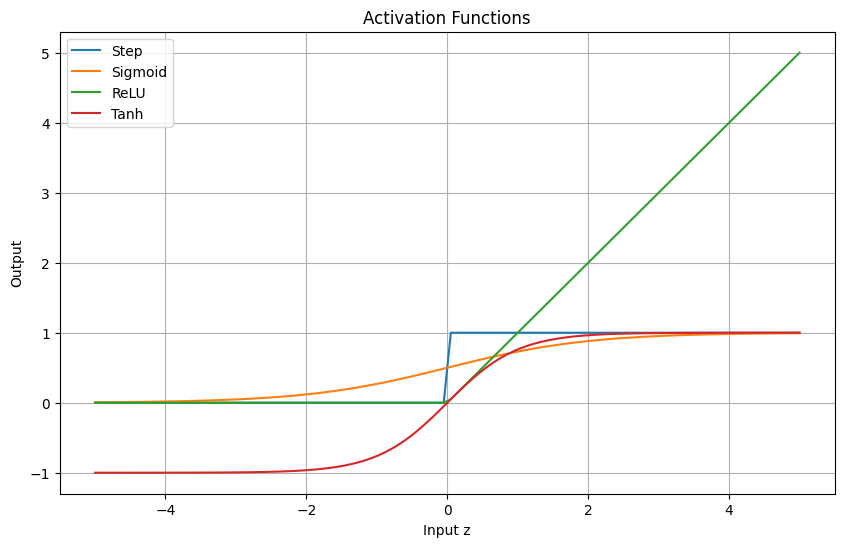

In [9]:
def step(z):
    return np.where(z >= 0, 1, 0)


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


def tanh(z):
    return np.tanh(z)


z = np.linspace(-5, 5, 100)

plt.figure(figsize=(10, 6))

plt.plot(z, step(z), label="Step")
plt.plot(z, sigmoid(z), label="Sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.plot(z, tanh(z), label="Tanh")

plt.title("Activation Functions")
plt.xlabel("Input z")
plt.ylabel("Output")
plt.legend()
plt.grid(True)

plt.show()

Understand forward propagation

In [11]:
def forward_propagation(X, W1, b1, W2, b2):

    # Hidden layer
    Z1 = np.dot(X, W1) + b1
    A1 = np.maximum(0, Z1)

    # Output layer
    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2

Initialize the neural network

In [12]:
np.random.seed(42)

input_size = 2
hidden_size = 8
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.1
b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (2, 8)
b1 shape: (1, 8)
W2 shape: (8, 1)
b2 shape: (1, 1)


Calculate predictions

In [13]:
Z1, A1, Z2, A2 = forward_propagation(
    X_train, W1, b1, W2, b2
)

print("Input shape:", X_train.shape)
print("Hidden layer output shape:", A1.shape)
print("Predicted output shape:", A2.shape)

print("\nFirst five predicted probabilities:")
print(A2[:5].flatten())

Input shape: (800, 2)
Hidden layer output shape: (800, 8)
Predicted output shape: (800, 1)

First five predicted probabilities:
[0.32489692 0.52195638 0.52970965 0.5250108  0.45542762]


Implement the loss function

We'll use binary cross-entropy loss because this is a binary classification problem.

Its formula is:

$$ L=-\frac{1}{m}\sum_{i=1}^{m} \left[ y_i\log(\hat y_i) +(1-y_i)\log(1-\hat y_i) \right] $$

Where:

m: Number of samples.
yi: Actual label.
 y^i: Predicted probability.

A lower loss generally indicates better predictions

In [14]:
def binary_cross_entropy(y_true, y_pred):

    epsilon = 1e-12

    y_pred = np.clip(
        y_pred,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# Calculate initial loss
y_train_reshaped = y_train.reshape(-1, 1)

initial_loss = binary_cross_entropy(
    y_train_reshaped,
    A2
)

print("Initial Loss:", initial_loss)

Initial Loss: 0.8400002531337273


Implement backpropagation

Backpropagation calculates how the loss changes with respect to each weight and bias.

These gradients tell us how the parameters should be adjusted to reduce the loss.

In [15]:
def backpropagation(X, Y, Z1, A1, A2, W2):

    m = X.shape[0]

    # Output layer gradients
    dZ2 = A2 - Y

    dW2 = np.dot(A1.T, dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Hidden layer gradients
    dA1 = np.dot(dZ2, W2.T)

    dZ1 = dA1 * (Z1 > 0)

    dW1 = np.dot(X.T, dZ1) / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    return dW1, db1, dW2, db2


dW1, db1, dW2, db2 = backpropagation(
    X_train,
    y_train_reshaped,
    Z1,
    A1,
    A2,
    W2
)

print("Backpropagation completed!")
print("Gradient W1 shape:", dW1.shape)
print("Gradient W2 shape:", dW2.shape)

Backpropagation completed!
Gradient W1 shape: (2, 8)
Gradient W2 shape: (8, 1)


Loss Functions and Optimization Algorithms

In [16]:
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


# Example predictions
actual = np.array([[1], [0], [1], [1]])

predicted = np.array([
    [0.9],
    [0.2],
    [0.7],
    [0.8]
])

print("MSE Loss:", mse_loss(actual, predicted))

print(
    "Binary Cross-Entropy:",
    binary_cross_entropy(actual, predicted)
)

MSE Loss: 0.045
Binary Cross-Entropy: 0.22708064055624455


| Loss function             | Common application        |
| ------------------------- | ------------------------- |
| Mean Squared Error        | Regression                |
| Binary Cross-Entropy      | Binary classification     |
| Categorical Cross-Entropy | Multiclass classification |


Implement Stochastic Gradient Descent (SGD)

SGD updates weights using the gradients calculated through backpropagation.

The update equation is:

$$ W_{\text{new}}=W_{\text{old}}-\eta dW $$

Where neta is the learning rate.


In [17]:
def sgd_update(W, b, dW, db, learning_rate=0.01):

    W = W - learning_rate * dW
    b = b - learning_rate * db

    return W, b


# Demonstration
sample_W = np.array([[0.5, 0.8]])
sample_b = np.array([[0.1]])

sample_dW = np.array([[0.2, -0.3]])
sample_db = np.array([[0.05]])

updated_W, updated_b = sgd_update(
    sample_W,
    sample_b,
    sample_dW,
    sample_db
)

print("Updated Weights:", updated_W)
print("Updated Bias:", updated_b)

Updated Weights: [[0.498 0.803]]
Updated Bias: [[0.0995]]


Implement the Adam optimizer

Adam combines ideas from momentum and adaptive learning rates.

It maintains moving averages of gradients and squared gradients:

In [18]:
class Adam:

    def __init__(
        self,
        learning_rate=0.001,
        beta1=0.9,
        beta2=0.999,
        epsilon=1e-8
    ):

        self.lr = learning_rate
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon

        self.t = 0
        self.m = None
        self.v = None

    def update(self, params, grads):

        if self.m is None:
            self.m = [
                np.zeros_like(p) for p in params
            ]

            self.v = [
                np.zeros_like(p) for p in params
            ]

        self.t += 1

        updated_params = []

        for i, (p, g) in enumerate(zip(params, grads)):

            self.m[i] = (
                self.beta1 * self.m[i]
                + (1 - self.beta1) * g
            )

            self.v[i] = (
                self.beta2 * self.v[i]
                + (1 - self.beta2) * (g ** 2)
            )

            m_hat = self.m[i] / (
                1 - self.beta1 ** self.t
            )

            v_hat = self.v[i] / (
                1 - self.beta2 ** self.t
            )

            p = p - self.lr * m_hat / (
                np.sqrt(v_hat) + self.epsilon
            )

            updated_params.append(p)

        return updated_params


print("Adam optimizer implemented successfully!")

Adam optimizer implemented successfully!


| Feature        | SGD                                 | Adam                                                    |
| -------------- | ----------------------------------- | ------------------------------------------------------- |
| Full name      | Stochastic Gradient Descent         | Adaptive Moment Estimation                              |
| Basic approach | Uses gradients to update parameters | Uses moving averages of gradients and squared gradients |
| Learning rate  | Usually fixed or scheduled          | Adapts update sizes for individual parameters           |
| Memory         | Low                                 | Requires additional memory                              |
| Typical use    | Many training tasks                 | Common default for neural network training              |


Build a Neural Network From Scratch Using NumPy

In [19]:
class NeuralNetwork:

    def __init__(
        self,
        input_size,
        hidden_size,
        output_size
    ):

        # Initialize weights and biases
        self.W1 = (
            np.random.randn(input_size, hidden_size)
            * np.sqrt(2 / input_size)
        )

        self.b1 = np.zeros((1, hidden_size))

        self.W2 = (
            np.random.randn(hidden_size, output_size)
            * 0.1
        )

        self.b2 = np.zeros((1, output_size))

        # Adam optimizer
        self.optimizer = Adam(learning_rate=0.001)

    def forward(self, X):

        # Hidden layer
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = np.maximum(0, self.Z1)

        # Output layer
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = sigmoid(self.Z2)

        return self.A2

    def backward(self, X, Y):

        m = X.shape[0]

        # Output layer gradients
        dZ2 = self.A2 - Y

        dW2 = np.dot(self.A1.T, dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        # Hidden layer gradients
        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * (self.Z1 > 0)

        dW1 = np.dot(X.T, dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        return dW1, db1, dW2, db2

    def train(
        self,
        X,
        Y,
        epochs=1000,
        batch_size=32
    ):

        losses = []
        n = X.shape[0]

        for epoch in range(epochs):

            # Shuffle training samples
            indices = np.random.permutation(n)

            X_shuffled = X[indices]
            Y_shuffled = Y[indices]

            # Train using mini-batches
            for start in range(0, n, batch_size):

                end = start + batch_size

                X_batch = X_shuffled[start:end]
                Y_batch = Y_shuffled[start:end]

                # Forward propagation
                predictions = self.forward(X_batch)

                # Backpropagation
                grads = self.backward(
                    X_batch,
                    Y_batch
                )

                dW1, db1, dW2, db2 = grads

                # Update weights using Adam
                params = [
                    self.W1,
                    self.b1,
                    self.W2,
                    self.b2
                ]

                gradients = [
                    dW1,
                    db1,
                    dW2,
                    db2
                ]

                params = self.optimizer.update(
                    params,
                    gradients
                )

                self.W1, self.b1, self.W2, self.b2 = params

            # Calculate loss for the entire training dataset
            predictions = self.forward(X)

            loss = binary_cross_entropy(
                Y,
                predictions
            )

            losses.append(loss)

            if (epoch + 1) % 100 == 0:
                print(
                    f"Epoch {epoch + 1}/{epochs}, "
                    f"Loss: {loss:.4f}"
                )

        return losses

    def predict(self, X):

        probabilities = self.forward(X)

        return (probabilities >= 0.5).astype(int)


train the network for 1,000 epochs.

An epoch represents one complete pass through the training dataset. Since we're using mini-batches, each epoch contains multiple parameter updates.

In [20]:
np.random.seed(42)

Y_train = y_train.reshape(-1, 1)

nn = NeuralNetwork(
    input_size=2,
    hidden_size=8,
    output_size=1
)

losses = nn.train(
    X_train,
    Y_train,
    epochs=1000,
    batch_size=32
)

print("\nTraining completed!")

Epoch 100/1000, Loss: 0.2507
Epoch 200/1000, Loss: 0.1469
Epoch 300/1000, Loss: 0.0621
Epoch 400/1000, Loss: 0.0380
Epoch 500/1000, Loss: 0.0307
Epoch 600/1000, Loss: 0.0259
Epoch 700/1000, Loss: 0.0222
Epoch 800/1000, Loss: 0.0201
Epoch 900/1000, Loss: 0.0188
Epoch 1000/1000, Loss: 0.0174

Training completed!


Plot the training loss

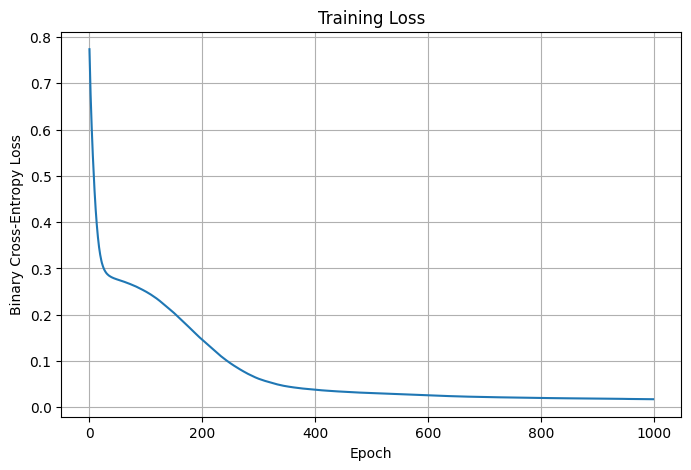

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(losses)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

Evaluate the trained neural network

In [22]:
y_pred = nn.predict(X_test)

accuracy = np.mean(
    y_pred.flatten() == y_test
)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Accuracy: 100.0 %


Visualize the decision boundary

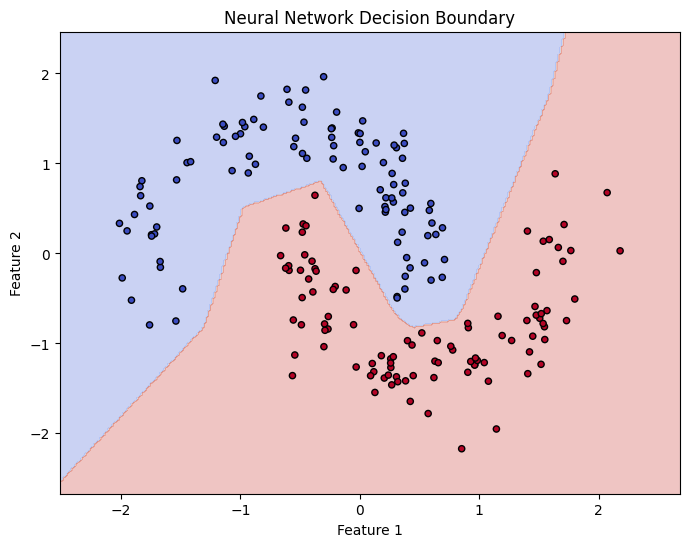

In [23]:
def plot_decision_boundary(model, X, y):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    predictions = model.predict(grid)

    predictions = predictions.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx,
        yy,
        predictions,
        alpha=0.3,
        cmap="coolwarm"
    )

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black",
        s=20
    )

    plt.title("Neural Network Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

    plt.show()


plot_decision_boundary(nn, X_test, y_test)

Save the neural network weights

In [24]:
np.savez(
    "neural_network_weights.npz",
    W1=nn.W1,
    b1=nn.b1,
    W2=nn.W2,
    b2=nn.b2
)

print("Neural network weights saved successfully!")

Neural network weights saved successfully!


load weights

In [25]:
saved_weights = np.load("neural_network_weights.npz")

nn_loaded = NeuralNetwork(
    input_size=2,
    hidden_size=8,
    output_size=1
)

nn_loaded.W1 = saved_weights["W1"]
nn_loaded.b1 = saved_weights["b1"]
nn_loaded.W2 = saved_weights["W2"]
nn_loaded.b2 = saved_weights["b2"]

print("Neural network weights loaded successfully!")

Neural network weights loaded successfully!


Verify the loaded neural network

In [27]:
original_predictions = nn.predict(X_test)

loaded_predictions = nn_loaded.predict(X_test)

same_predictions = np.array_equal(
    original_predictions,
    loaded_predictions
)

print(
    "Predictions match:",
    same_predictions
)

Predictions match: True


Save the scaler

In [28]:
joblib.dump(
    scaler,
    "feature_scaler.joblib"
)

loaded_scaler = joblib.load(
    "feature_scaler.joblib"
)

print("Feature scaler saved and loaded successfully!")

Feature scaler saved and loaded successfully!


Make Predictions on New Data

In [29]:
# Example raw input with two features
new_sample = np.array([[0.5, 0.2]])

# Apply the same scaling used during training
new_sample_scaled = loaded_scaler.transform(
    new_sample
)

# Predict using the loaded neural network
prediction = nn_loaded.predict(
    new_sample_scaled
)

probability = nn_loaded.forward(
    new_sample_scaled
)[0, 0]

print("Predicted Class:", int(prediction[0, 0]))
print("Probability of Class 1:", round(float(probability), 4))

Predicted Class: 1
Probability of Class 1: 0.6846


Interpretation:

Predicted Class 0: The network classifies the sample as Class 0.
Predicted Class 1: The network classifies the sample as Class 1.
The probability indicates the network's estimated probability of Class 1.

This is a simple example of using a trained model for inference.

| No. | Requirement                          | Completed in    |
| --- | ------------------------------------ | --------------- |
| 1   | Import machine learning libraries    | Cell 1          |
| 2   | Create and prepare a dataset         | Cells 2–3       |
| 3   | Train a machine learning model       | Cell 4          |
| 4   | Save and load using pickle           | Cells 5–6       |
| 5   | Save and load using joblib           | Cell 7          |
| 6   | Implement a perceptron               | Cell 8          |
| 7   | Activation functions                 | Cell 9          |
| 8   | Forward propagation                  | Cells 10–12     |
| 9   | Loss functions                       | Cells 13 and 15 |
| 10  | Backpropagation                      | Cell 14         |
| 11  | SGD optimizer                        | Cell 16         |
| 12  | Adam optimizer                       | Cell 17         |
| 13  | Build a neural network from scratch  | Cell 18         |
| 14  | Train the neural network             | Cell 19         |
| 15  | Visualize the training loss          | Cell 20         |
| 16  | Evaluate model accuracy              | Cell 21         |
| 17  | Visualize the decision boundary      | Cell 22         |
| 18  | Save and load neural network weights | Cells 23–25     |
| 19  | Save and load the feature scaler     | Cell 26         |
| 20  | Make predictions on new data         | Cell 27         |
